# Ten new 114-feature varied AI pilots and a forecasting corpus

Train ten independent AI pilots from scratch with the current 23-skill SkillManager catalogue, using the hostile-missile- and radar-aware runtime controller. Each pilot receives a reproducibly sampled Transformer width/head/layer configuration and PPO value/entropy coefficients. After training, collect a two-sided NN-versus-NN corpus in the style of notebook 31.

Each controller receives the exact 114-feature policy frame: the compact 47-value aircraft/friendly-missile state, four hostile-missile slots (40 values), 23 mathematically encoded radar-state features, and four energy features. The corpus stores those frames at 10 Hz, 20-frame histories at each 1 Hz decision, physical aircraft/missile tracks, selected skill IDs and one-hot labels, decoded SkillManager parameters, and raw NN parameter vectors for future skill/manoeuvre forecasting.

This notebook creates a new sequentially numbered population and corpus. It does not continue or overwrite notebook-30 checkpoints.


## Setup

Install dependencies from the repository root, then restart the kernel:

```bash
python -m pip install -e '.[ml,video]'
```

For GPU training, install a CUDA-enabled PyTorch build in the selected kernel's
environment and restart the kernel. See `docs/multi_pilot_training.md` for setup.
Policy inference and PPO updates use CUDA when available; JSBSim and opponent
control run in separate CPU processes so Python control code can use multiple cores.
Processes are reused across epochs. `BVR_PILOT_DEVICE` can explicitly select a device.
After a code update, restart the kernel and run from the top; confirm the configuration
prints `simulator_executor: process`. The first flight batch includes worker startup.
`BVR_PILOT_EXECUTOR=thread` restores the previous collector for a timing comparison.

For an installation check, set `BVR_PILOT_EPOCHS=1`, `BVR_PILOT_EPISODE_SECONDS=1`,
`BVR_PILOT_SCENARIOS=3`, `BVR_PILOT_EVALUATION_SCENARIOS=3`, and
`BVR_PILOT_UPDATE_EPOCHS=1` before starting Jupyter. This notebook always creates ten pilots. Set `BVR_PILOT_OPPONENT=tactical` to train against the tactical opponent; the default is `simple`.
To leave capacity for VS Code and other work, `BVR_PILOT_WORKERS` defaults to 80%
of the logical CPU count, rounded down with a minimum of one worker. `BVR_PILOT_TORCH_THREADS`
caps PyTorch CPU operations at up to 8 threads by default. Both are configurable
before setup; explicit environment values override the defaults. These limits
reduce concurrency but do not reserve specific cores or guarantee a CPU percentage.
CUDA graphs accelerate full PPO minibatches by replaying their GPU operations together.
The 50 update passes, batch size of 64, optimizer, rewards, and validation stay the same.
CPU execution and partial minibatches use the ordinary update path. Set
`BVR_PILOT_CUDA_GRAPHS=0` before setup to disable capture for comparisons.
Notebook 04 retains its ordinary update path. Restart the kernel after code changes.

The progress bar identifies flight collection, PPO updates, validation, and replay saving.
CPU load falls during GPU updates. Compare `rollout_seconds`, `update_seconds`, and
`checkpoint_seconds` in the saved metrics. `cuda_graph_updates: 1` confirms graph use;
`simulator_effective_cores` measures CPU use during simulator steps.

In [ ]:
import json
import os
from dataclasses import replace
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Leave CPU capacity for the editor and other applications.
DEFAULT_SIMULATOR_WORKERS = max(1, ((os.cpu_count() or 1) * 80) // 100)
TORCH_THREADS = int(os.getenv(
    "BVR_PILOT_TORCH_THREADS", str(min(8, DEFAULT_SIMULATOR_WORKERS))
))
if TORCH_THREADS < 1:
    raise ValueError("BVR_PILOT_TORCH_THREADS must be positive")
torch.set_num_threads(TORCH_THREADS)

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "bvr_behavior_prediction").exists():
    REPO_ROOT = REPO_ROOT.parent
for source_root in (REPO_ROOT, REPO_ROOT / "bvr_sim_source"):
    if str(source_root) not in sys.path:
        sys.path.insert(0, str(source_root))

from bvr_behavior_prediction.rl.bvr_jsbsim_backend import BVRJSBSimBackend
from bvr_behavior_prediction.rl.config import PilotTrainingConfig
from bvr_behavior_prediction.rl.environment import BluePilotEnvironment
from bvr_behavior_prediction.rl.multi_pilot import PilotSpec, train_pilots, load_trained_pilot
from bvr_behavior_prediction.rl.dogfight_reward import (
    dogfight_population_weights, hybrid_dogfight_reward_definition,
)
from bvr_behavior_prediction.rl.trainer import PPOTrainer
from bvr_behavior_prediction.rl.observation_features import (
    RADAR_POLICY_OBSERVATION_SIZE, RADAR_FEATURE_NAMES,
)
from bvr_behavior_prediction.rl.population_variations import (
    SAMPLER_VERSION, sample_training_variations,
)

SEED = int(os.getenv("BVR_PILOT_SEED", "7"))
VARIATION_SEED = int(os.getenv("BVR_PILOT_VARIATION_SEED", "42"))
OPPONENT_TYPE = os.getenv("BVR_PILOT_OPPONENT", "simple")
if OPPONENT_TYPE not in ("simple", "tactical"):
    raise ValueError("BVR_PILOT_OPPONENT must be simple or tactical")
TRANSFORMER_HEADS = (4, 8)
# Matched initialization and scenarios isolate reward preferences; architecture and
# PPO loss variations are sampled independently and recorded per pilot.
SEED_STRIDE = int(os.getenv("BVR_PILOT_SEED_STRIDE", "0"))
evaluation_seed_value = os.getenv("BVR_PILOT_EVALUATION_SEED")
EVALUATION_SEED = int(evaluation_seed_value) if evaluation_seed_value else None
EPOCHS = int(os.getenv("BVR_PILOT_EPOCHS", "80"))
EPISODE_SECONDS = float(os.getenv("BVR_PILOT_EPISODE_SECONDS", "120"))
PILOT_COUNT = int(os.getenv("BVR_PILOT_COUNT", "10"))
if PILOT_COUNT != 10:
    raise ValueError("This notebook intentionally creates exactly ten new pilots")
MAX_WINDOWS_PATH = 240
def assert_path_budget(*paths):
    for path in paths:
        absolute = str(Path(path).resolve())
        if len(absolute) > MAX_WINDOWS_PATH:
            raise ValueError(f"Path is too long for Windows-safe output: {len(absolute)} > {MAX_WINDOWS_PATH}: {absolute}")

def next_short_batch_id(parent):
    parent = Path(parent)
    parent.mkdir(parents=True, exist_ok=True)
    requested = os.getenv("BVR_PILOT_BATCH_ID")
    if requested is not None:
        if not requested.isdigit() or not 1 <= int(requested) <= 9999:
            raise ValueError("BVR_PILOT_BATCH_ID must be a number from 0001 to 9999")
        return f"{int(requested):04d}"
    used = [int(path.name) for path in parent.iterdir()
            if path.is_dir() and path.name.isdigit() and len(path.name) == 4]
    next_value = max(used, default=0) + 1
    if next_value > 9999:
        raise RuntimeError("No four-digit pilot batch IDs remain")
    return f"{next_value:04d}"

BATCH_ROOT = Path(os.getenv("BVR_PILOT_BATCH_ROOT",
                            REPO_ROOT / "artifacts/rl_pilot_notebook/hybrid"))
assert_path_budget(BATCH_ROOT)
BATCH_ID = next_short_batch_id(BATCH_ROOT)
OUTPUT_DIR = Path(os.getenv(
    "BVR_PILOT_OUTPUT", BATCH_ROOT / BATCH_ID
)).resolve()
assert_path_budget(
    OUTPUT_DIR, OUTPUT_DIR / "pilot_001" / "simulator_logs",
    OUTPUT_DIR / "pilot_001" / "final_evaluation" / "scenario_000_seed_4294967295.txt.acmi",
    OUTPUT_DIR / "pilot_001" / "demonstrations" / "epoch_9999" / "blue_vs_red.acmi",
)
DEVICE = os.getenv("BVR_PILOT_DEVICE", "cuda" if torch.cuda.is_available() else "cpu")
print({"device": DEVICE, "pilot_count": PILOT_COUNT, "epochs_per_pilot": EPOCHS,
       "torch_version": torch.__version__, "cuda_available": torch.cuda.is_available(),
       "torch_threads": torch.get_num_threads(), "output": str(OUTPUT_DIR)})

## 114-feature radar-aware runtime controller

The hostile-missile slots are simulator-truth features, sorted by range and UID, with zero padding. The radar block encodes scan/STT mode, track presence, wrapped antenna angles, body-relative radar direction, scan-zone/beam state, sweep direction, and validity. This matches the frame submitted to the NN and the frame later stored by the forecasting corpus exporter.


In [2]:
BASE_OBSERVATION_SIZE = BVRJSBSimBackend.HOSTILE_MISSILE_RADAR_OBSERVATION_SIZE
ENERGY_FEATURES = 4
OBSERVATION_SIZE = BASE_OBSERVATION_SIZE + ENERGY_FEATURES
assert OBSERVATION_SIZE == RADAR_POLICY_OBSERVATION_SIZE == 114


def make_environment_factory(run_config):
    def bvr_jsbsim_backend_factory(scenario_dict, recording_path=None):
        return BVRJSBSimBackend(
            scenario_dict,
            recording_path=recording_path,
            log_dir=run_config.output_dir / "simulator_logs",
            opponent_type=OPPONENT_TYPE,
            include_hostile_missiles=True,
            include_radar_features=True,
            episode_duration_s=run_config.episode_duration_s,
        )

    def make_environment(scenario, recording_path=None):
        return BluePilotEnvironment(
            bvr_jsbsim_backend_factory,
            scenario,
            planning_horizon_s=run_config.planning_horizon_s,
            episode_duration_s=run_config.episode_duration_s,
            history_duration_s=run_config.history_duration_s,
            sample_interval_s=run_config.sample_interval_s,
            recording_path=recording_path,
        )

    return make_environment


## Configure style priorities and shared combat guidance

Each pilot optimizes evade, pursue, and eliminate with different **relative** weights.
Weights sum to one; increasing one priority reduces the others.
`dogfight_population_weights(PILOT_COUNT)` spreads any positive number of pilots across
the preference triangle. Its default minimum weight of 0.1 keeps every objective relevant.
Pilot IDs are identifiers, not claims about learned aggression or defensive ability.

- **Evade:** defeat unique incoming missiles while minimizing time under active threat.
  Missile rewards are capped per flight so repeated threats cannot pay indefinitely.
- **Pursue:** improve the best engagement position reached during the flight. Closeness
  stops increasing the score inside the nominal 30 km engagement range; alignment can
  still improve. Returning to a previously reached position gives no extra reward.
- **Eliminate:** receive one weighted reward for a confirmed missile elimination.

Every pilot also shares a **+100 confirmed-elimination reward** and **-150 aircraft-loss
penalty**. Total elimination reward is therefore 125 to 300 for the default roster.
These give all pilots a reason to finish the engagement while allowing different priorities.

Small shared learning bonuses help every pilot learn the combat mechanics:

| Guidance | Maximum reward per flight |
| --- | --- |
| First target lock | +2, paid once |
| First launch with a lock | +8, paid once |
| Maintain lock while a live friendly missile's own seeker is inactive | +5, spread over at most 20 seconds |

All guidance together is capped at **15**. Repeated lock acquisition and repeated firing
cannot multiply those bonuses. Support credit ends when the lock is lost, the missile's
seeker activates, or the missile or target dies. These are bounded heuristic bonuses;
they are not a guarantee of optimal behaviour. Altitude and selecting a named skill
carry no separate bonuses. The current 23-skill catalogue and simple opponent remain.

The common comparison benchmark disables the three guidance bonuses and scores outcomes
and style objectives with equal weights. Each pilot selects checkpoints using its own
training objective. Notebook **04 keeps its original `CombatReward`**, including its
original lock/launch/evasion/outcome weights; both recipes remain available.

For a controlled reward comparison, the default uses the **same seed** for each fresh
model, optimizer, and training scenario set. Use `BVR_PILOT_SEED_STRIDE=1000` for different
seeds per pilot, or repeat the roster with another `BVR_PILOT_SEED` to assess variability.
All pilots share a separate validation set for checkpoint selection. Reserve fresh
scenarios and opponents for final tests. Inspect outcomes and replays before assigning styles.

Edit `STYLE_WEIGHTS`, `REWARD_SETTINGS`, or supply your own `RewardDefinition` factories.
See `docs/multi_pilot_training.md` for the formula and alternative recipes.

### Per-pilot architecture and PPO variation

The ten fresh pilots use a deterministic sampler with widths `(56, 64, 72, 96)`, Transformer heads `(4, 8)`, layers `(1, 2, 3)`, value coefficients in `[0.45, 0.55]`, and entropy coefficients in `[0.009, 0.011]`. Widths are divisible by both head counts. Each effective configuration is recorded in the population manifest and the pilot's training metadata.

In [3]:
STYLE_WEIGHTS = dogfight_population_weights(PILOT_COUNT)
REWARD_SETTINGS = {
    "episode_duration_s": EPISODE_SECONDS,
    "evasion_cap": 4,
    "pursuit_range_m": 30_000.0,
    "loss_penalty": 0.6,
    "reward_scale": 250.0,
    "elimination_bonus": 100.0,
    "lock_bonus": 2.0,
    "launch_bonus": 8.0,
    "dumb_launch_penalty": -8.0,
    "support_bonus": 5.0,
    "support_budget_s": 20.0,
}


def make_reward_definition(pilot_index):
    return hybrid_dogfight_reward_definition(
        f"hybrid_objective_{pilot_index + 1:03d}",
        weights=STYLE_WEIGHTS[pilot_index], **REWARD_SETTINGS,
    )


WIDTH_CHOICES = (56, 64, 72, 96)
LAYER_CHOICES = (1, 2, 3)
VALUE_COEFFICIENT_RANGE = (0.45, 0.55)
ENTROPY_COEFFICIENT_RANGE = (0.009, 0.011)
TRAINING_VARIATIONS = sample_training_variations(
    PILOT_COUNT, seed=VARIATION_SEED, widths=WIDTH_CHOICES, layers=LAYER_CHOICES,
    transformer_heads=TRANSFORMER_HEADS,
    value_coefficient_range=VALUE_COEFFICIENT_RANGE,
    entropy_coefficient_range=ENTROPY_COEFFICIENT_RANGE,
)
PILOTS = [
    PilotSpec(
        pilot_id=f"pilot_{index + 1:03d}",
        seed=SEED + SEED_STRIDE * index,
        reward=make_reward_definition(index),
        training_overrides=TRAINING_VARIATIONS[index],
    )
    for index in range(PILOT_COUNT)
]
BENCHMARK_SETTINGS = {
    **REWARD_SETTINGS, "lock_bonus": 0.0, "launch_bonus": 0.0, "support_bonus": 0.0,
}
COMMON_REWARD = hybrid_dogfight_reward_definition("common_hybrid_dogfight", **BENCHMARK_SETTINGS)
VARIATION_ROSTER = [
    {"pilot_id": pilot.pilot_id, "seed": pilot.seed,
     **pilot.training_overrides,
     **{f"reward_{key}": value for key, value in pilot.reward.parameters["weights"].items()}}
    for pilot in PILOTS
]
VARIATION_TABLE = pd.DataFrame(VARIATION_ROSTER)
POPULATION_METADATA = {
    "experiment": "radar_varied_transformer_hybrid_v1",
    "opponent_type": OPPONENT_TYPE,
    "observation": {
        "schema": "compact_hostile_missiles_radar_energy_v1",
        "frame_size": OBSERVATION_SIZE,
        "hostile_missile_slots": BVRJSBSimBackend.HOSTILE_MISSILE_SLOTS,
        "hostile_missile_features": list(BVRJSBSimBackend.HOSTILE_MISSILE_FEATURE_NAMES),
        "radar_features": list(RADAR_FEATURE_NAMES),
        "source": "simulator_truth", "order": "range_then_uid",
    },
    "sampler": SAMPLER_VERSION, "variation_seed": VARIATION_SEED,
    "width_choices": list(WIDTH_CHOICES), "layer_choices": list(LAYER_CHOICES),
    "value_coefficient_range": list(VALUE_COEFFICIENT_RANGE),
    "entropy_coefficient_range": list(ENTROPY_COEFFICIENT_RANGE),
    "transformer_heads": list(TRANSFORMER_HEADS),
    "roster": VARIATION_ROSTER,
}
display(VARIATION_TABLE)
print("Variation seed:", VARIATION_SEED)

,pilot_id,seed,hidden_size,transformer_layers,transformer_heads,value_coefficient,entropy_coefficient,reward_evade,reward_pursue,reward_eliminate
0,pilot_001,7,56,3,8,0.535860,0.010395,0.333333,0.333333,0.333333
1,pilot_002,7,64,1,4,0.547562,0.010522,0.100000,0.100000,0.800000
2,pilot_003,7,72,3,8,0.495039,0.009742,0.100000,0.800000,0.100000
3,pilot_004,7,56,1,8,0.514387,0.010646,0.800000,0.100000,0.100000
4,pilot_005,7,72,2,4,0.505458,0.009128,0.100000,0.333333,0.566667
5,pilot_006,7,56,3,8,0.513166,0.010516,0.100000,0.566667,0.333333
6,pilot_007,7,72,2,4,0.539312,0.010557,0.333333,0.100000,0.566667
7,pilot_008,7,96,3,4,0.496672,0.009088,0.333333,0.566667,0.100000
8,pilot_009,7,72,1,8,0.524476,0.010935,0.566667,0.100000,0.333333
9,pilot_010,7,72,2,4,0.487046,0.009939,0.566667,0.333333,0.100000


Variation seed: 42


In [ ]:
config = PilotTrainingConfig(
    seed=SEED,
    evaluation_seed=EVALUATION_SEED,
    epochs=EPOCHS,
    episode_duration_s=EPISODE_SECONDS,
    planning_horizon_s=1.0,
    history_duration_s=2.0,
    sample_interval_s=0.1,
    transformer_heads=4,
    transformer_layers=2,
    scenarios_per_epoch=int(os.getenv("BVR_PILOT_SCENARIOS", "50")),
    evaluation_scenarios_per_epoch=int(os.getenv("BVR_PILOT_EVALUATION_SCENARIOS", "50")),
    simulator_workers=int(os.getenv("BVR_PILOT_WORKERS", str(DEFAULT_SIMULATOR_WORKERS))),
    simulator_executor=os.getenv("BVR_PILOT_EXECUTOR", "process"),
    reuse_simulator_environments=True,
    selected_skill_parameters=True,
    hidden_size=64,
    learning_rate=3e-4,
    update_epochs=int(os.getenv("BVR_PILOT_UPDATE_EPOCHS", "50")),
    minibatch_size=64,
    cuda_graph_updates=os.getenv("BVR_PILOT_CUDA_GRAPHS", "1") != "0",
    checkpoint_interval=max(1, EPOCHS // 5),
    demonstration_interval=int(os.getenv("BVR_PILOT_DEMONSTRATION_INTERVAL", "0")),
    diagnostic_interval=1,
    output_dir=OUTPUT_DIR,
    mlflow_experiment="jsbsim-hybrid-population",
    mlflow_tracking_uri=f"sqlite:///{(REPO_ROOT / 'artifacts/mlflow.db').as_posix()}",
)
# Explicit pilot definitions above override the legacy config.reward field.
print(json.dumps({"opponent_type": OPPONENT_TYPE, **{key: value for key, value in config.as_dict().items()
                  if key != "reward"}}, indent=2))

## Train the ten varied new pilots

Each pilot is initialized from scratch with its own sampled Transformer and PPO settings. The output directory must be new; checkpoint and population metadata are retained for corpus reproduction.

The PPO objective follows notebook 31: `policy_loss + value_coefficient * value_loss - entropy_coefficient * entropy`. `selected_skill_parameters=True` means the sampled skill's parameter log-probability and entropy are used, with the same masked hybrid-action calculation. The hybrid reward also carries notebook 31's `dumb_launch_penalty=-8`: every launch request reported without radar lock contributes one `fired_without_lock` event, including a launch request rejected by the simulator. The effective architecture and loss coefficients are recorded per pilot.


In [ ]:
results = train_pilots(
    pilots=PILOTS,
    config=config,
    env_factory_builder=make_environment_factory,
    observation_size=OBSERVATION_SIZE,
    device=DEVICE,
    benchmark_reward=COMMON_REWARD,
    population_metadata=POPULATION_METADATA,
)
summary = pd.DataFrame(results)
comparison = summary.merge(VARIATION_TABLE, on=["pilot_id", "seed"], validate="one_to_one")
display(summary[[
    "pilot_id", "seed", "reward_name", "selection_return", "benchmark_return",
    "survival_rate", "elimination_rate", "checkpoint",
]])
display(comparison[["pilot_id", "hidden_size", "transformer_layers",
                 "transformer_heads", "value_coefficient",
                 "entropy_coefficient", "network_parameters",
                 "benchmark_return"]])
print(f"Batch manifest: {OUTPUT_DIR / 'pilots.json'}")

In [ ]:
# Select any completed pilot for inspection. This does not rerun training.
SELECTED_PILOT = os.getenv("BVR_PILOT_VIEW", results[0]["pilot_id"])
selected_result = next(result for result in results if result["pilot_id"] == SELECTED_PILOT)
selected_spec = next(pilot for pilot in PILOTS if pilot.pilot_id == SELECTED_PILOT)
RUN_DIR = OUTPUT_DIR / selected_result["output_dir"]
selected_config = replace(
    config, **selected_spec.training_overrides, seed=selected_spec.seed,
    evaluation_seed=selected_result["evaluation_seed"], output_dir=RUN_DIR,
)
trainer = PPOTrainer(
    make_environment_factory(selected_config), OBSERVATION_SIZE, selected_config,
    device=DEVICE, reward_definition=selected_spec.reward,
)
trainer.pilot.load_state_dict(load_trained_pilot(RUN_DIR, DEVICE).state_dict())
trained_pilot = trainer.pilot.eval()

FINAL_EVALUATION_DIR = RUN_DIR / "final_evaluation"
FINAL_EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
final_evaluation_rollouts = []
final_evaluation_manifest = []
for index, scenario in enumerate(trainer.evaluation_scenarios):
    episode_seed = selected_config.resolved_evaluation_seed + index
    acmi_path = FINAL_EVALUATION_DIR / f"scenario_{index:03d}_seed_{episode_seed}.txt.acmi"
    rollout, score, final_info = trainer._episode(
        scenario, episode_seed, recording_path=acmi_path, deterministic=True,
    )
    final_evaluation_rollouts.append(rollout)
    final_evaluation_manifest.append({
        "pilot_id": SELECTED_PILOT,
        "checkpoint_sha256": selected_result["checkpoint_sha256"],
        "reward": selected_spec.reward.as_dict(),
        "training_overrides": selected_spec.training_overrides,
        "scenario_index": index, "seed": episode_seed, "score": score,
        "scenario": scenario.as_dict(), "final_info": final_info, "acmi": acmi_path.name,
    })

manifest_path = FINAL_EVALUATION_DIR / "manifest.json"
manifest_path.write_text(json.dumps(final_evaluation_manifest, indent=2, default=str), encoding="utf8")
print(f"Recorded {len(final_evaluation_manifest)} replays for {SELECTED_PILOT}")
print(f"ACMI directory: {FINAL_EVALUATION_DIR}")

## Compare the pilots

The common benchmark uses equal evade/pursue/eliminate weights for every pilot on the
same validation scenarios, with lock/launch/support bonuses disabled. The common
elimination reward and loss penalty still apply. The component table separates trade-offs, while
survival, confirmed eliminations, missiles avoided, and time under threat give outcomes
without each pilot's own preference weights. `elimination_rate` requires a confirmed
missile kill; `opponent_destroyed_rate` in the manifest includes any opponent death.

These are validation results, not evidence of generalization to unseen opponents.
Avoided-missile counts depend on how many threats a pilot encounters: read them together
with exposure and survival, and inspect replays before assigning style labels.

Each pilot also has its own training curves. Compare those reward totals only within
that pilot's objective. Evaluation occurs on the first, last, and every fifth epoch;
only fresh evaluation points are plotted. Loss need not fall monotonically.
The JSONL files and `pilots.json` can be reloaded later without retraining.

In [7]:
batch_manifest = json.loads((OUTPUT_DIR / "pilots.json").read_text(encoding="utf8"))
completed = [pilot for pilot in batch_manifest["pilots"] if pilot["status"] == "completed"]
summary = pd.DataFrame(completed)
metrics_by_pilot = {
    pilot["pilot_id"]: pd.read_json(
        OUTPUT_DIR / pilot["output_dir"] / "training_metrics.jsonl", lines=True
    )
    for pilot in completed
}
display(summary[["pilot_id", "benchmark_return", "survival_rate", "elimination_rate",
                 "mean_missiles_avoided", "mean_threatened_seconds"]])
display(pd.DataFrame([
    {"pilot_id": pilot["pilot_id"], **pilot["benchmark_component_means"]}
    for pilot in completed
]).set_index("pilot_id"))

,pilot_id,benchmark_return,survival_rate,elimination_rate,mean_missiles_avoided,mean_threatened_seconds
0,pilot_001,-73.405128,0.52,0.00,2.44,58.358
1,pilot_002,-81.264843,0.50,0.00,2.38,63.268
2,pilot_003,-68.792132,0.54,0.00,2.68,58.734
3,pilot_004,-63.252917,0.58,0.00,3.10,67.406
4,pilot_005,-73.632295,0.54,0.00,2.70,69.472
5,pilot_006,-83.494766,0.48,0.00,2.42,64.144
6,pilot_007,-82.674415,0.50,0.00,2.26,63.640
7,pilot_008,-78.646491,0.48,0.00,2.74,61.064
8,pilot_009,-46.239715,0.40,0.34,1.84,56.708
9,pilot_010,-51.486303,0.36,0.30,1.62,51.778


,combat_elimination,dumb_launch,eliminate,evade,lock_acquired,locked_launch,loss,missile_support,pursue
pilot_id,,,,,,,,,
pilot_001,0.0,0.00,0.000000,-4.693056,0.0,0.0,-72.0,0.0,3.287927
pilot_002,0.0,0.00,0.000000,-6.436111,0.0,0.0,-75.0,0.0,0.171268
pilot_003,0.0,0.00,0.000000,-1.620833,0.0,0.0,-69.0,0.0,1.828701
pilot_004,0.0,0.00,0.000000,-1.809722,0.0,0.0,-63.0,0.0,1.556805
pilot_005,0.0,0.00,0.000000,-7.827778,0.0,0.0,-69.0,0.0,3.195483
pilot_006,0.0,0.00,0.000000,-6.627778,0.0,0.0,-78.0,0.0,1.133012
pilot_007,0.0,0.00,0.000000,-9.611111,0.0,0.0,-75.0,0.0,1.936696
pilot_008,0.0,0.00,0.000000,-2.405556,0.0,0.0,-78.0,0.0,1.759065
pilot_009,34.0,-8.80,28.333333,-11.047222,0.0,0.0,-90.0,0.0,1.274174


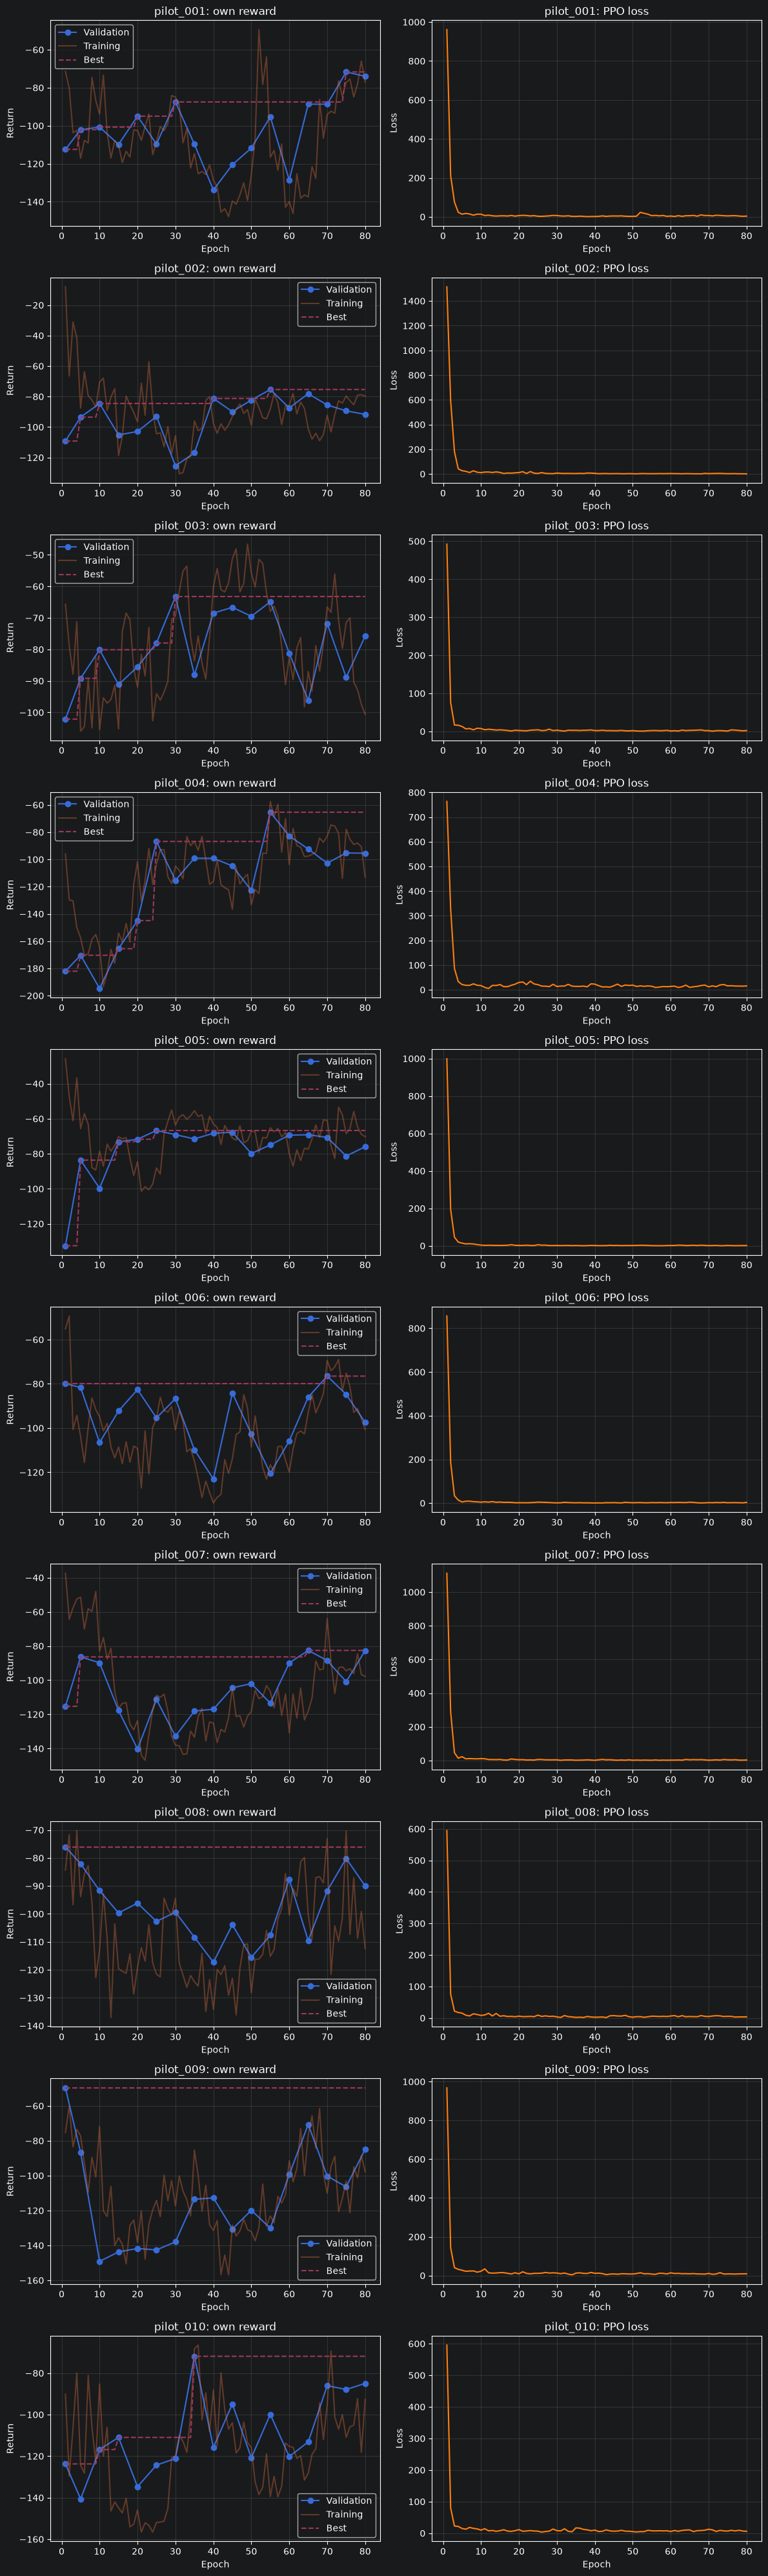

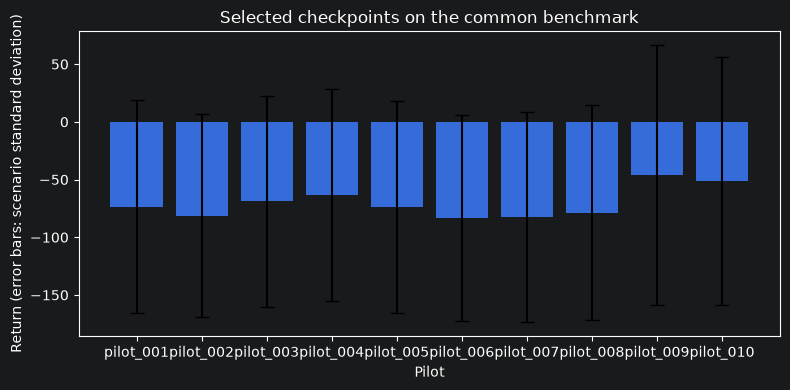

In [8]:
figure, axes = plt.subplots(len(completed), 2, figsize=(12, 4 * len(completed)), squeeze=False)
for row, pilot in enumerate(completed):
    metrics = metrics_by_pilot[pilot["pilot_id"]]
    evaluated = metrics[metrics["evaluation_performed"] == 1]
    axes[row, 0].plot(evaluated["epoch"], evaluated["mean_return"], marker="o", label="Validation")
    axes[row, 0].plot(metrics["epoch"], metrics["training_mean_return"], alpha=0.4, label="Training")
    axes[row, 0].plot(metrics["epoch"], metrics["best_return"], linestyle="--", label="Best")
    axes[row, 0].set(title=f"{pilot['pilot_id']}: own reward", xlabel="Epoch", ylabel="Return")
    axes[row, 0].legend()
    axes[row, 1].plot(metrics["epoch"], metrics["loss"], color="tab:orange")
    axes[row, 1].set(title=f"{pilot['pilot_id']}: PPO loss", xlabel="Epoch", ylabel="Loss")
    for axis in axes[row]:
        axis.grid(alpha=0.25)
figure.tight_layout()
plt.show()

figure, axis = plt.subplots(figsize=(8, 4))
axis.bar(summary["pilot_id"], summary["benchmark_return"],
         yerr=summary["benchmark_return_std"], capsize=5)
axis.set(title="Selected checkpoints on the common benchmark",
         xlabel="Pilot", ylabel="Return (error bars: scenario standard deviation)")
figure.tight_layout()
plt.show()

## Inspect the selected pilot

The replay cell saves the selected pilot's checkpoint hash and reward definition alongside
every ACMI flight. Change `BVR_PILOT_VIEW` or `SELECTED_PILOT` in that cell to inspect
another completed pilot. Open the `.txt.acmi` files in Tacview for the full flights.

In [ ]:
rollout = final_evaluation_rollouts[0]
first_evaluation = final_evaluation_manifest[0]
evaluation_return = first_evaluation["score"]
final_info = first_evaluation["final_info"]
print(f"Example ACMI: {FINAL_EVALUATION_DIR / first_evaluation['acmi']}")
selected_skills = [trained_pilot.skill_names[index] for index in rollout.skills]
skill_counts = pd.Series(selected_skills).value_counts().rename_axis("skill").rename("decisions")
print(f"Evaluation return: {evaluation_return:.2f}")
display(skill_counts.to_frame())

skill_counts.sort_values().plot.barh(figsize=(8, max(3, len(skill_counts) * 0.35)))
plt.title("Skills selected in the first fixed evaluation rollout")
plt.xlabel("Decisions")
plt.tight_layout()
plt.show()


## Generate the forecasting corpus

Run the dedicated current-branch collector after training. It runs the ten fresh pilots against one another, records both aircraft perspectives, and writes a schema/checksum manifest. Independent flights are collected in up to eight CPU processes by default; set `BVR_CORPUS_WORKERS=1` for serial debugging. Reduce `BVR_CORPUS_FLIGHTS` for an installation check.


In [ ]:
import subprocess
CORPUS_FLIGHTS = int(os.getenv("BVR_CORPUS_FLIGHTS", "10000"))
CORPUS_SEED = int(os.getenv("BVR_CORPUS_SEED", "26110600"))
CORPUS_EPISODE_SECONDS = float(os.getenv("BVR_CORPUS_EPISODE_SECONDS", "300"))
CORPUS_WORKERS = int(os.getenv("BVR_CORPUS_WORKERS", "0"))
CORPUS_OUTPUT = Path(os.getenv(
    "BVR_CORPUS_OUTPUT", REPO_ROOT / "shared/corpora/nn-duels-current" / BATCH_ID
)).resolve()
assert_path_budget(CORPUS_OUTPUT, CORPUS_OUTPUT / "A01" / "observations" / "nn_00000000_00000.parquet")
collector = REPO_ROOT / "scripts" / "generate_forecasting_corpus.py"
command = [
    sys.executable, str(collector), "--population", str(OUTPUT_DIR),
    "--output", str(CORPUS_OUTPUT), "--flights", str(CORPUS_FLIGHTS),
    "--seed", str(CORPUS_SEED), "--episode-seconds", str(CORPUS_EPISODE_SECONDS),
    "--workers", str(CORPUS_WORKERS),
]
completed = subprocess.run(command, capture_output=True, text=True)
if completed.stdout:
    print(completed.stdout, end="")
if completed.returncode:
    if completed.stderr:
        print(completed.stderr, end="", file=sys.stderr)
    raise RuntimeError(f"Corpus collector failed with exit code {completed.returncode}: {command!r}")
corpus_manifest = json.loads((CORPUS_OUTPUT / "manifest.json").read_text(encoding="utf8"))
corpus_schema = json.loads((CORPUS_OUTPUT / "schema.json").read_text(encoding="utf8"))
assert corpus_manifest["observation_size"] == RADAR_POLICY_OBSERVATION_SIZE == 114
assert len(corpus_schema["observation_columns"]) == RADAR_POLICY_OBSERVATION_SIZE
print(json.dumps({
    "corpus": str(CORPUS_OUTPUT),
    "physical_flights": corpus_manifest["physical_flights"],
    "perspective_episodes": corpus_manifest["perspective_episodes"],
    "observation_size": corpus_manifest["observation_size"],
}, indent=2))


## Forecasting data contract

For each perspective, `observations/` contains the exact 114-channel radar-aware runtime frames; `tracks/` contains simulator-truth aircraft state and missile counts; and `target_decisions/` contains the selected skill, catalogue index, one-hot skill encoding, decoded parameter JSON, raw NN parameter vector, and a SHA-256 hash of the submitted 20-frame history.

Use `schema.json` and `skill_catalogue.json` as the authoritative feature/label ordering when preparing future skill or manoeuvre forecasters. Keep both perspectives from one physical flight in the same split using `scenario_group`.
